# 07-OneNET平台配置与OTA接口联调


## 1. 本篇范围与实验目标

第06篇解决了ESP32-C3烧入ESP-AT固件、连接Wi-Fi和发送HTTP请求。本篇把请求对象换成OneNET：**在平台放好升级包和任务，再通过PC接口工具、ESP串口命令分别验证检测任务、分片下载和状态上报。**

对应讲义《OTA远程升级》物理页65—69，以及视频27—31：

| 视频 | 最后字幕时间 | 主要内容 |
|---|---:|---|
| 27 无线OTA_WiFi远程升级引言&流程 | 06:01 | 为什么需要无线升级，App/Bootloader分工 |
| 28 无线OTA_OneNET平台_创建产品&设备&升级任务 | 06:19 | 产品、设备、升级包、升级任务 |
| 29 无线OTA_OneNET平台_检测升级任务&Token生成 | 12:47 | 接口参数、Token资源与生成、检测结果 |
| 30 无线OTA_OneNET平台_下载升级包&上报升级状态 | 11:09 | Range、二进制文件和step状态码 |
| 31 无线OTA_OneNET平台_AT指令测试接口 | 08:08 | 把通过PC验证的HTTP请求搬到ESP-AT |

资料来自[课程网盘](https://pan.baidu.com/s/19vzB65qjPtH6BEy0EBZ5VQ?pwd=1234)，提取码 `1234`。正文对照五段视频完整自动字幕、讲义原图、配套源码及OneNET公开文档。自动字幕中的平台名、接口名和指令拼写按原图与文档校正；没有逐帧完整观看视频。

**本篇没有创建真实云产品/设备、上传固件、发送真实升级状态，也没有进行串口或开发板测试。** 操作步骤用于复现课程；所有产品ID、设备名、密钥和Token均用占位符或明确的示例值。状态上报会改变测试设备的云端任务状态，实际联调时应使用自己的专用测试任务。

学完本篇，应能回答：云端任务如何与设备对应；Authorization从哪里来；怎样拿到目标版本与任务ID；怎样请求第0—99字节；怎样区分下载完成和升级完成。


## 2. 无线升级整体链路：平台、App、Bootloader各做什么

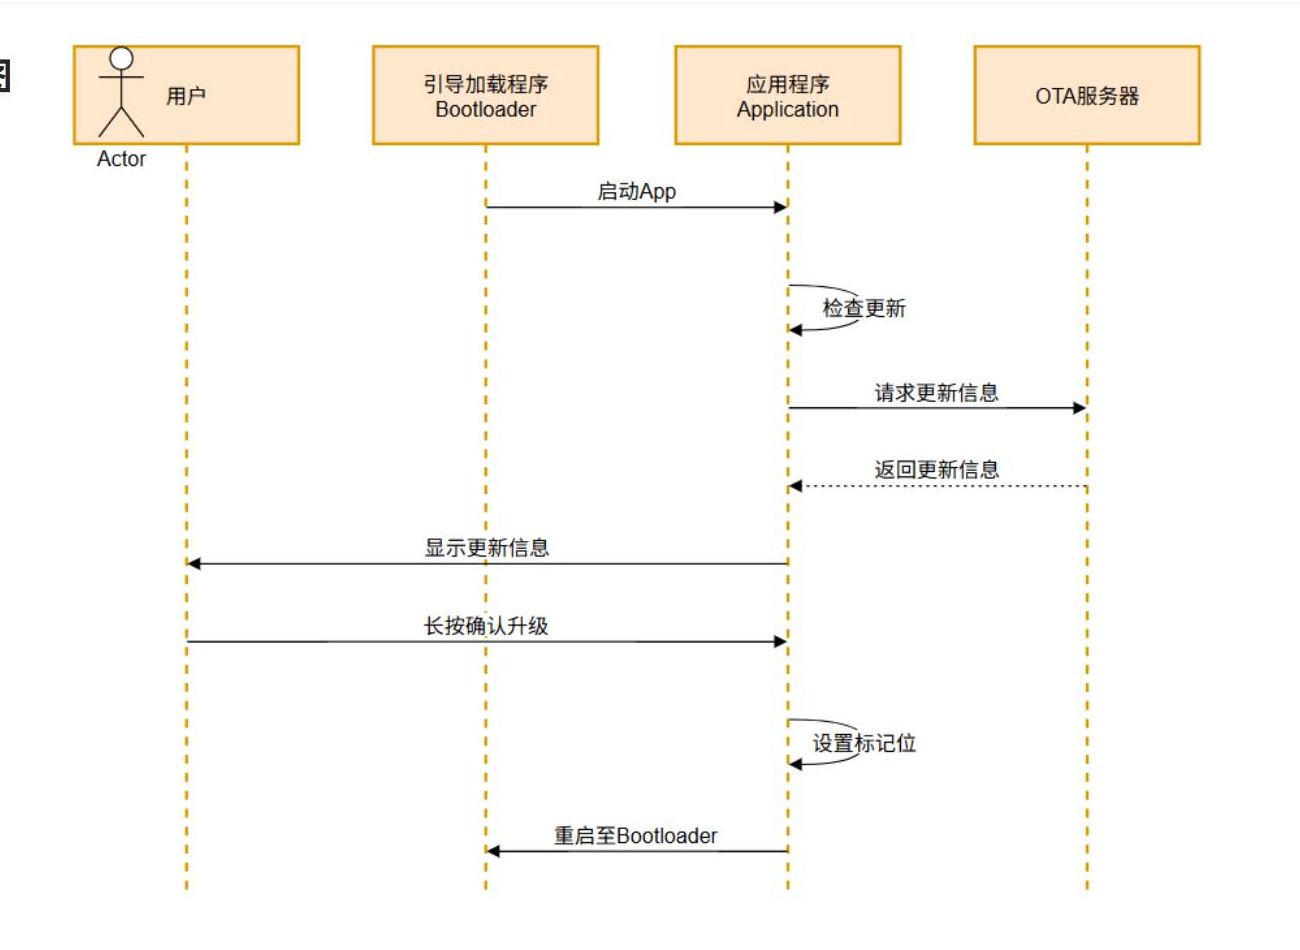

*讲义第67页泳道图主体，沿参与方和时间顺序理解；本篇先验证其中云端接口。*

课堂场景是：设备已经交付给用户，程序后续需要修复或增加功能。再让用户把设备拆下、接下载器或串口工具不方便，于是让设备经Wi-Fi取得新固件。

```text
开发者：编译新App → 上传bin → 创建升级任务
平台：保存升级包、目标版本、任务和设备状态
App：联网 → 查询任务 → 显示新版本 → 等待用户确认
用户：长按确认升级
App：写升级标志 → 主控复位
Bootloader：联网 → 分片下载 → 校验 → 替换App → 处理结果并启动
```

ESP32-C3负责Wi-Fi和HTTP通信，GD32通过AT串口控制它；OTA最终要更新的是**GD32的App固件**。不要把本篇下载的GD32 bin当成ESP-AT固件烧给ESP。

平台不直接操作GD32的Flash。接口能返回数据，只能证明请求和鉴权这部分可用；实际落盘、校验、搬运、启动和失败恢复由设备端实现。

本课采用“设备主动查询”的方式。控制台建好任务不等于固件已经主动推送进设备；设备还要使用正确身份和当前版本请求check，再按任务ID取数据。


## 3. OneNET对象关系：先分清产品、设备、包和任务

| 对象 | 含义 | 在请求中如何使用 |
|---|---|---|
| 产品 Product | 一类设备的抽象模型 | 产品ID进入接口路径和Token资源 |
| 设备 Device | 产品下的一台具体设备 | 设备名进入路径，参与设备级鉴权 |
| 升级包 | 上传的固件及目标版本信息 | check返回size、md5、target |
| 升级任务 | 把某个包安排给哪些设备、何时升级 | 每台设备检测到任务后取得tid |
| 设备升级状态 | 该设备在本任务中的进度和结果 | status接口通过step更新 |

建议先在本地记下自己的实验参数：

```text
PRODUCT_ID = 你的产品ID
DEVICE_NAME = 你的测试设备名
CURRENT_VERSION = 设备当前实际版本，例如1.0
TARGET_VERSION = 本次新包版本，例如1.6
TASK_ID = check返回的tid，不能自己猜
TOKEN = 按资源和对应密钥生成的完整鉴权串
```

本文示例 `1.0`、`1.6` 只用于解释当前/目标的区别。课程不同演示阶段使用过带 `v` 的版本；平台、设备和请求要统一自己的版本字符串，`1.0` 与 `v1.0` 不能默认当成相同。

产品级Token和设备级Token的资源不同，密钥来源也不同。产品ID、设备名称、任务ID、设备密钥、生成后的Token不是同一个概念，不能互相替代。


## 4. 控制台准备：创建产品与测试设备

视频28的操作顺序：

1. 登录OneNET控制台，进入产品开发相关入口。
2. 创建一个产品；课堂选了加湿器类目，填写产品名称和所属地区，其余接入配置基本沿用页面默认值。
3. 打开该产品的设备管理，添加测试设备。
4. 用英文、数字等符合页面规则的名称区分设备；视频建了两台，方便观察各设备任务状态。
5. 记录产品ID和设备名；需要生成鉴权时，再从对应产品/设备的密钥入口取自己的密钥。

**产品只是模型，设备才代表具体实例。** 平台模板里的属性、命令并不意味着已经有一块真实硬件连接上来。

课程创建产品时选择的接入协议为MQTT，数据协议为JSON；本篇用HTTP OTA接口完成操作，并没有在此实现一套MQTT客户端。不要把产品页面的默认接入选项误写成“本篇通过MQTT下载固件”。

视频中的设备初始显示未激活，随后通过通信继续实验，没有单独演示一个“激活按钮”操作。实际平台的接入、授权和状态显示若有变化，以当前账号控制台和对应文档为准，不保证所有新页面都和旧课一致。

本步骤的可检查结果：产品下确实存在自己的测试设备，路径里将使用的名字与控制台完全一致。不要把设备备注名或展示名错当成接口要求的设备名。


## 5. 上传升级包并创建任务

课程在“增值服务/OTA升级”入口首次开通相关功能，然后添加升级包。视频当时的开通方式和价格只代表课堂界面，本笔记不把它当成当前套餐承诺。

上传时关注：

| 项目 | 作用 | 核对要点 |
|---|---|---|
| 包名称 | 控制台中识别固件 | 能区分版本与用途 |
| 所属产品 | 限定该包对应产品 | 选刚创建的产品 |
| 目标版本 | 升级后预期版本 | 与固件编译版本保持一致 |
| 固件文件 | 实际要下载的字节流 | 上传适配目标App地址的bin |
| 文件大小/MD5 | 下载校验依据 | 与本地同一文件核对 |

bin是目标应用的机器码，不是C源文件、Keil工程、HEX文本或压缩包。单独App的链接起点、向量表和Bootloader分区要匹配，不能“随便上传一个能编译出的bin”就认为一定能启动。

创建升级任务时，视频选择批量升级，选择“未上传版本”的测试设备作为待升级对象，设置任务名，并把超时放长到24小时，便于后续编程测试。平台也提供先验证少量设备再批量升级的入口；课程为演示直接走了批量流程。

这里的“全部设备”是课堂专门创建的少量测试设备，不应直接套到自己已有的所有生产设备。实际复现可以只指定专用测试设备，达到同样的接口验证目标。

建好后，设备任务应处于待升级阶段。若后面check没有返回预期任务，先回控制台确认：任务未过期/取消、设备确实在任务范围中、当前版本与筛选条件一致、包属于该产品。


## 6. 三个核心接口：先在PC验证，再搬到AT串口

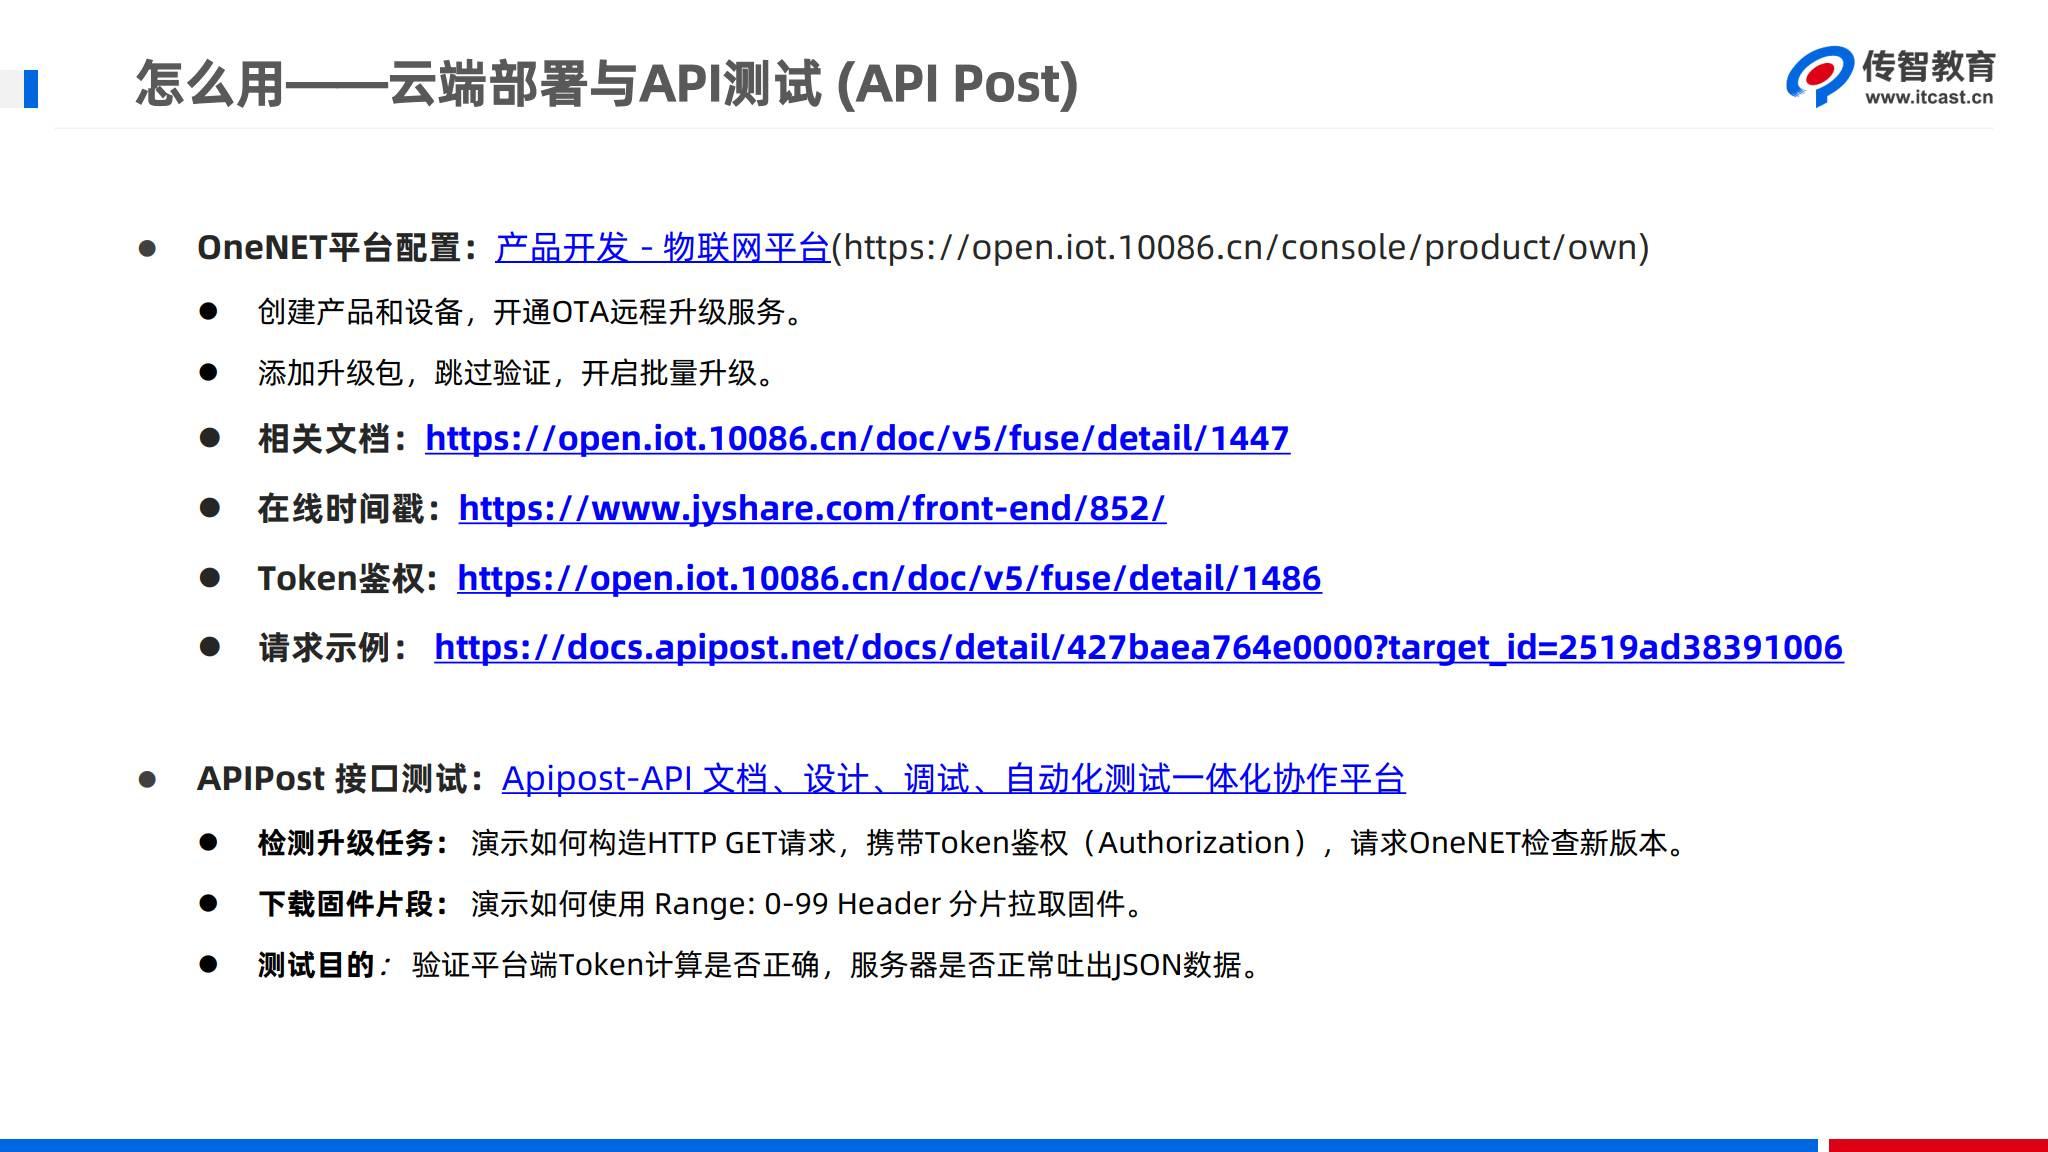

*讲义第68页，平台部署后按检测、下载、上报三类接口联调。具体字段以本篇核对的官方文档为准。*

| 操作 | 方法 | 接口路径后缀 | 请求体 |
|---|---|---|---|
| 检测升级任务 | GET | `/{pro_id}/{dev_name}/check` | 无 |
| 下载升级包 | GET | `/{pro_id}/{dev_name}/{tid}/download` | 无 |
| 上报升级状态 | POST | `/{pro_id}/{dev_name}/{tid}/status` | JSON，`{"step":...}` |

共同基础地址：

```text
https://iot-api.heclouds.com/fuse-ota
```

共同请求头：

```http
Authorization: 完整TOKEN
```

视频用APIPost先验证HTTP层，因为它能独立查看URL、请求头、JSON响应和二进制文件。PC请求成功后，再把相同的路径、Token和参数放入 `AT+HTTPCLIENT`，这样容易区分：

```text
PC也失败：优先检查平台对象、任务、Token和接口参数
PC成功、AT失败：再检查Wi-Fi、AT格式、转义、串口与响应
AT成功、GD32程序失败：再检查接收长度、解析和状态机
```

不要为了一个接口错误同时修改Token算法、串口接线和Flash代码。分层验证能减少无关变量。


## 7. Token由什么构成：版本、资源、时间、方法和签名

课程使用设备密钥鉴权生成工具，最终输出类似：

```text
version=2018-10-31&res=URL编码后的资源&et=未来Unix秒&method=md5&sign=编码后的签名
```

这是一行完整字符串，放入Authorization头；不是普通登录密码，也不是把设备密钥原样粘进去。

| 参数 | 本课含义 | 易错点 |
|---|---|---|
| `version` | 鉴权参数版本，课程为 `2018-10-31` | 与App固件版本无关 |
| `res` | 受授权的资源路径 | 与产品/设备及密钥匹配 |
| `et` | 到期Unix时间戳，单位秒 | 不能填毫秒，不能用已过期的课堂值 |
| `method` | HMAC使用的摘要方法 | md5/sha1/sha256按所用方案选择 |
| `sign` | 计算后编码的签名 | 不是普通MD5文件校验值 |

资源和密钥的配对：

| 作用范围 | 未URL编码的res | 使用的key |
|---|---|---|
| 产品级 | `products/PRODUCT_ID` | 该产品的密钥 |
| 设备级 | `products/PRODUCT_ID/devices/DEVICE_NAME` | 该设备的密钥 |

例如资源写成设备级路径，却拿产品key或别台设备key生成，可能得到格式看似完整但无法通过校验的Token。资源大小写、设备名和签名原文也不能随意变更。

官方check接口示例页面还出现了 `version=2022-05-01&res=userid/...` 的另一套鉴权示例。**不要把它的version/res与课程2018-10-31设备密钥方案拼接。** 复现应选定一种受接口支持的完整方案，并使用相应文档、资源和密钥。


## 8. 用工具生成Token，并理解签名顺序

视频29使用配套Token生成工具，依次填入鉴权版本、资源、过期时间、方法和key。课程选择md5方法，用未来时间让实验期内Token可用，再把生成结果复制到Authorization。

按官方算法，课程方案的核心步骤为：

```text
1. res使用未编码资源路径参与签名
2. stringToSign = et + "\n" + method + "\n" + res + "\n" + version
3. keyBytes = Base64Decode(accessKey)
4. rawSign = HMAC(method, keyBytes, UTF8(stringToSign))
5. sign = Base64(rawSign)
6. 组装参数时对res、sign等value进行URL编码
```

`method=md5` 表示 **HMAC-MD5**，不是直接 `MD5(stringToSign)`；这也与下载固件后计算的文件MD5不同。

理解算法的Python示意（未执行真实密钥生成）：

```python
import base64
import hashlib
import hmac
from urllib.parse import urlencode, quote

def device_token(product_id, device_name, access_key_b64, expires):
    version = "2018-10-31"
    method = "md5"
    res = f"products/{product_id}/devices/{device_name}"
    et = str(expires)  # 未来Unix秒
    message = "\n".join([et, method, res, version]).encode("utf-8")
    key = base64.b64decode(access_key_b64, validate=True)
    digest = hmac.new(key, message, hashlib.md5).digest()
    sign = base64.b64encode(digest).decode("ascii")
    return urlencode(
        [("version", version), ("res", res), ("et", et),
         ("method", method), ("sign", sign)],
        quote_via=quote, safe=""
    )
```

这段用于解释签名与编码顺序；实际实验可直接用配套工具，不需要为了调用接口重新实现算法。key不能硬编码进公开笔记、截图或仓库。

生成前检查本机时间和目标过期时间；生成后检查字符串没有意外换行、前后引号或空格。工具已输出URL编码后的完整Token时，**直接作为Header值，不要再整体URL编码一次**，否则 `%2F` 可能变成 `%252F`。


## 9. 检测升级任务：路径、query与返回字段

请求模板：

```http
GET /fuse-ota/PRODUCT_ID/DEVICE_NAME/check?type=1&version=1.0 HTTP/1.1
Host: iot-api.heclouds.com
Authorization: TOKEN
```

完整URL：

```text
https://iot-api.heclouds.com/fuse-ota/PRODUCT_ID/DEVICE_NAME/check?type=1&version=1.0
```

这里有两个容易混淆的 `type`：

| 出现位置 | 值 | 含义 |
|---|---:|---|
| 请求query `type` | 1 / 2 | FOTA任务 / SOTA任务 |
| 响应 `data.type` | 1 / 2 | 完整包 / 差分包 |

本课操作FOTA，使用 `type=1`。query里的 `version` 是**设备当前版本**，不是你准备升级到的目标版本，也不是Token的鉴权版本。

以下为便于说明的合法JSON示例，数值是示例值：

```json
{
  "code": 0,
  "msg": "succ",
  "request_id": "example-request",
  "data": {
    "target": "1.6",
    "tid": 123,
    "size": 32656,
    "md5": "0123456789abcdef0123456789abcdef",
    "status": 1,
    "type": 1
  }
}
```

| 字段 | 后续用途 |
|---|---|
| `code` | 0表示本次业务请求成功；不能只看HTTP状态 |
| `target` | 新版本名称，给界面和升级校验使用 |
| `tid` | 任务ID，后续download/status必须沿用 |
| `size` | 固件总字节数，决定分片与容量检查 |
| `md5` | 整包指纹，用于下载完成后比对 |
| `status` | 1待升级、2下载中、3升级中 |
| `data.type` | 本课处理完整包；不能直接把差分包当完整bin安装 |

上面MD5是刻意使用的示例值，不能拿来校验课程bin。应保存真实check返回值，并对照自己上传的同一份文件。


## 10. APIPost检测操作与本地文件核对

PC侧操作：

1. 新建GET请求，填写自己的check完整URL。
2. 在Query中确认 `type=1` 和真实当前 `version`；若URL已经带参数，不要再在另一处重复添加同名值。
3. 在Headers添加 `Authorization`，值为完整Token。
4. 发送，检查HTTP响应、JSON中的 `code`、`msg` 和 `data`。
5. 把真实 `tid`、`size`、`target`、`md5` 记录在本次测试记录里。
6. 回到控制台，确认设备和任务相对应。

视频展示返回大小32656字节，并与本地固件大小核对。复现实验时自己的编译结果可能不同，**以自己上传的文件为准，不强求与视频相同字节数**。

Windows可对本地文件计算MD5：

```powershell
Get-FileHash -Algorithm MD5 -LiteralPath 'C:\OTA-Test\app.bin'
(Get-Item -LiteralPath 'C:\OTA-Test\app.bin').Length
```

将输出的哈希按大小写无关方式与 `data.md5` 比较，并核对字节数。文件名相同不能说明内容相同；后来又编译了一次但未重新上传，也会导致本地文件和云端包不一致。

MD5用于本课的完整性比对，不能替代固件签名和来源真实性验证。实际安全启动需要额外机制，这里先掌握接口与整包一致性。

APIPost帮助站点在本次自动读取中受robots限制，未能读取帮助正文；以上步骤依据课程操作与OneNET文档整理，不依赖该站点的额外说明。


## 11. 分片下载：Range是闭区间，0-99表示100字节

拿到任务ID后，调用：

```http
GET /fuse-ota/PRODUCT_ID/DEVICE_NAME/123/download HTTP/1.1
Host: iot-api.heclouds.com
Authorization: TOKEN
Range: 0-99
```

这里的 `123` 是示例任务ID，必须替换成真实check结果。

**课程所用旧版OneNET接口规定Range值直接写 `0-99`，不加 `bytes=`。** 不要把其他HTTP服务常用的 `bytes=0-99` 格式机械套到这里。实际服务如果升级，应按对应接口文档重新验证格式。

| Range值 | 含义 |
|---|---|
| `0-99` | 偏移0到99，前100字节 |
| `100-199` | 偏移100到199，接着100字节 |
| `0-` | 从偏移0到文件结束 |
| `2-` | 从偏移2，也就是第3个字节到结束 |
| `-100` | 最后100字节 |

长度计算：

```text
本片长度 = end - start + 1
下一片start = 已成功接收并保存的累计字节数
end = min(start + 每片目标字节数, 总大小) - 1
```

例如32656字节文件，每片1024字节，正常前两片为 `0-1023`、`1024-2047`，最后一片是 `31744-32655`，长度912字节。

官方旧接口还说明：end超出文件会被截到最后；start大于end或超出文件范围时，start可能被重置为0；缺失或格式错误的Range可能直接返回整个文件。**设备必须自己检查offset、范围和响应长度，不能依赖越界请求来探测下载结束。** 否则有可能反复拿到文件开头，造成重复写入甚至无限循环。

本课先用100字节验证格式；后续可用512/1024等大小分片，但应结合串口接收缓冲、协议开销、AT限制和Flash写入能力选择。


## 12. 二进制响应、长度和下载错误

下载接口返回文件流，不是JSON正文。PC工具把原始字节强行按UTF-8等方式显示时，可能出现乱码、控制字符或空白，这并不证明固件损坏。

应切换到保存响应/二进制查看方式，下载到本地后按HEX检查；比对同一份原始bin的相应字节。不要把屏幕上显示的乱码复制回文本文件当成固件。

响应中值得检查的字段：

| 字段 | 含义 |
|---|---|
| `Content-Disposition` | 文件名等信息 |
| `Content-Range` | 本次范围与总长度 |
| `Content-Length` | 本次响应数据的字节数 |
| `Ota-Errno` | OneNET文件获取错误 |

`Ota-Errno` 对照：

| 值 | 含义 |
|---:|---|
| 0 | 成功 |
| 1 | 设备不存在 |
| 2 | 文件资源不存在 |
| 3 | 对象存储中资源不存在 |
| 4 | 获取文件失败，大小不一致 |
| 5 | 参数错误，或任务已过期/完成 |
| 6 | 鉴权失败 |

PC可以查看HTTP头，不等于ESP的 `AT+HTTPCLIENT` 也会把所有原始头逐字转交给MCU；AT侧应按固件实际输出格式解析数据长度。

后续GD32接收时，应按明确的字节长度保存原始payload，不能用 `strlen()` 计算固件长度：bin内可能包含 `0x00`。还要分清AT响应前缀、有效数据、尾部OK和异步消息，不能把它们一起写入Flash。

整包下载完成后，应累计校验大小和MD5。单片拿到100字节只证明这片返回了数据，不代表整包已完整或能启动。


## 13. 上报下载进度与完成：100和101二选一

请求：

```http
POST /fuse-ota/PRODUCT_ID/DEVICE_NAME/123/status HTTP/1.1
Host: iot-api.heclouds.com
Authorization: TOKEN
Content-Type: application/json

{"step":20}
```

`step` 是JSON数值，不要写成 `"20%"` 或 `{"status":20}`。

根据本次核对的官方文档：

| step | 作用 |
|---|---|
| 0—99 | 下载进度百分比；设备处于下载中时才能上报 |
| 100 | 下载进度达到100%，平台转入升级中 |
| 101 | 另一种“升级包下载成功”状态，同样转入升级中 |
| 201 | 升级成功，设备版本更新为任务目标版本 |

**上报100之后不能再报101。** 两者都表示下载阶段结束，应在自己的上报设计里选择一种。进入升级中后，也不能继续按下载中规则上报20、50等进度。

整型进度通常可按 `已成功保存字节数 × 100 / 总大小` 计算，乘法要用足够宽的类型。但不要在还没完成最后长度/完整性判断时，先把平台置为下载完成。本篇不提供一个每片自动上报到100、然后又发送101的错误循环。

视频演示曾通过上报进度使平台设备状态变为下载中；当前文档明确限定了允许上报的设备状态。复现时先查询平台实际状态，若返回 `invalid state`，要检查状态条件和任务生命周期，不能把任意step当成可随时重复发送的日志。


## 14. 失败码与升级成功码：不要把HTTP 200当step

| 阶段 | step | 说明 |
|---|---:|---|
| 下载失败 | 102 | 空间不足 |
| 下载失败 | 103 | 内存溢出 |
| 下载失败 | 104 | 下载请求超时 |
| 下载失败 | 105 | 电量不足 |
| 下载失败 | 106 | 信号不良 |
| 下载失败 | 107 | 未知异常 |
| 升级成功 | 201 | 平台把设备版本修改为任务目标版本 |
| 升级失败 | 202 | 电量不足 |
| 升级失败 | 203 | 内存溢出 |
| 升级失败 | 204 | 包与任务目标版本不一致 |
| 升级失败 | 205 | MD5校验失败 |
| 升级失败 | 206 | 未知异常 |
| 升级失败 | 207 | 达到最大重试次数 |

视频演示过程中把完成码填错后又改为201。应记住：

```text
HTTP 200：HTTP层面的响应状态
JSON code = 0：OneNET本次接口业务请求成功
POST {"step":201}：设备向OneNET报告本任务升级成功
```

**200不是这份OTA文档规定的升级成功业务码。** 也不能因为status接口返回code=0，就反过来认为设备Flash中的程序一定已经升级；那只说明这次上报被接受。

任务进入已取消、失败或成功等终态后，不能继续按活动任务上报上述状态。下载中可以报允许的下载/升级状态；升级中只能报升级阶段的状态。调试时若手动上报201，本任务可能就结束了，后面再次download或check的表现随之改变。

状态上报是会改变云端业务状态的操作。实际产品应该在真正完成相应阶段后才报告，笔记里保留步骤不代表本机已经执行这些操作。


## 15. 串口手动联调准备：把PC请求搬到ESP-AT

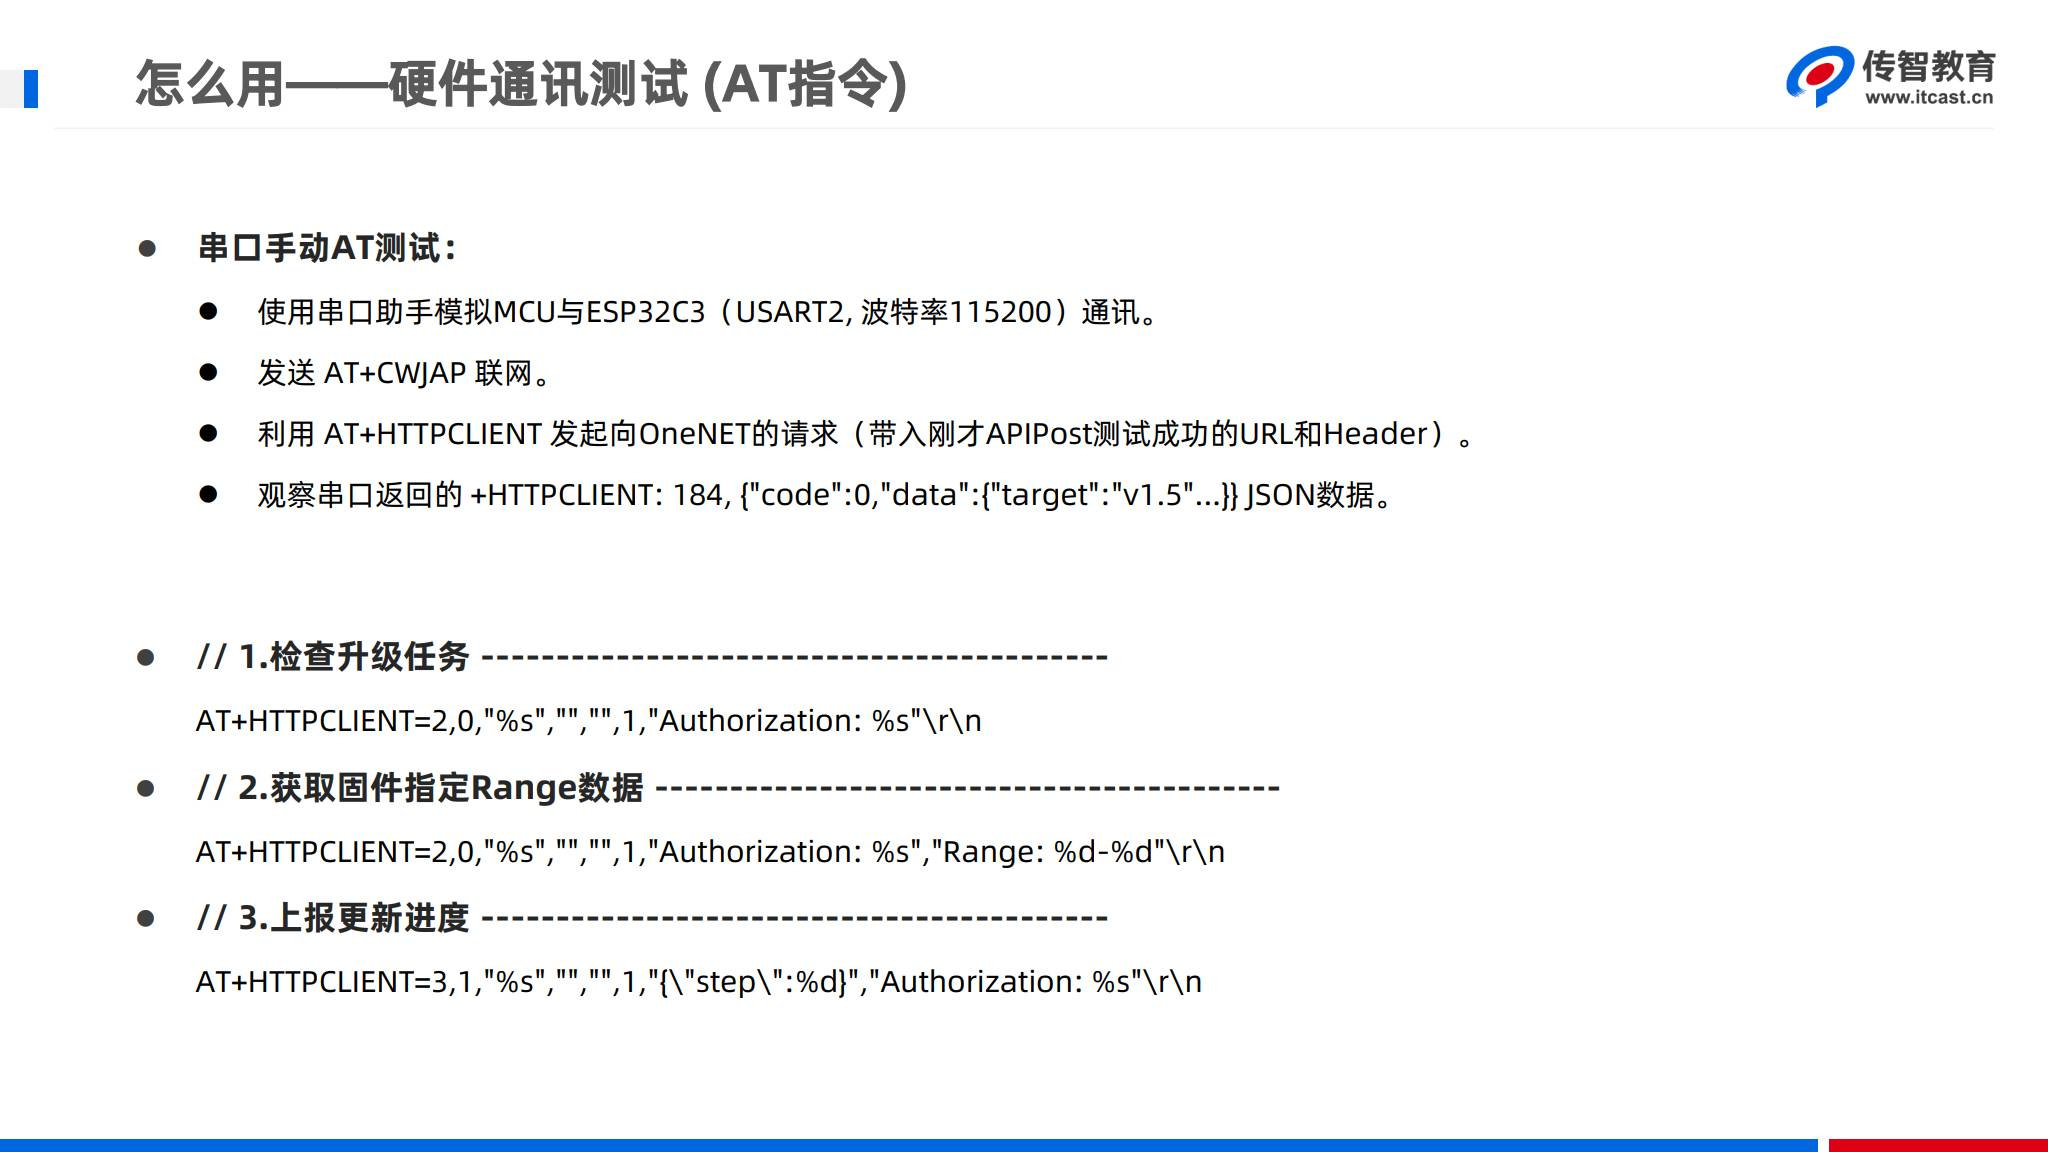

*讲义第69页：PC先代替MCU发AT命令，分别验证检测、分片下载和状态上报。*

先按第06篇连接ESP的AT UART，设置115200波特率并发送CR LF。此阶段PC通过USB-TTL控制ESP；第08篇再把同一AT口接到GD32的USART2。

最小准备命令：

```text
AT
ATE0
AT+CWMODE=1
AT+CWJAP="YOUR_SSID","YOUR_WIFI_PASSWORD"
```

等待联网完成和取得IP，再发送HTTP指令。SSID/密码替换为自己的，注意2.4 GHz热点和正确转义。`ATE0` 只关闭命令回显，不关闭真正的响应。

课堂AT模板使用完整URL，并以 `transport_type=1` 请求普通HTTP。前面PC示例使用HTTPS，搬到AT时URL与transport也要配套：

```text
课堂基线： http://...  + transport_type 1
HTTPS实验：https://... + transport_type 2，并核对该固件的TLS/证书配置
```

不能只把URL从http改成https却仍保留不匹配的传输类型。HTTP明文会传输Authorization，本篇保留课程语法用于理解；实际部署应评估并验证HTTPS方式。

以下模板里的 `PRODUCT_ID`、`DEVICE_NAME`、`TASK_ID`、`TOKEN` 都是占位符，必须换成当前实验真实值后发送；每条末尾由串口工具添加CR LF，等待本条结果再发下一条。


## 16. 三条AT模板与HTTPCLIENT参数

检测任务，GET：

```text
AT+HTTPCLIENT=2,0,"http://iot-api.heclouds.com/fuse-ota/PRODUCT_ID/DEVICE_NAME/check?type=1&version=1.0","","",1,"Authorization: TOKEN"
```

分片下载，GET：

```text
AT+HTTPCLIENT=2,0,"http://iot-api.heclouds.com/fuse-ota/PRODUCT_ID/DEVICE_NAME/TASK_ID/download","","",1,"Authorization: TOKEN","Range: 0-99"
```

上报状态，POST。以下 `20` 仅为格式示例，发送前要确认自己的任务允许上报该状态：

```text
AT+HTTPCLIENT=3,1,"http://iot-api.heclouds.com/fuse-ota/PRODUCT_ID/DEVICE_NAME/TASK_ID/status","","",1,"{\"step\":20}","Authorization: TOKEN"
```

参数读法：

| 位置/值 | 本课含义 |
|---|---|
| opt=2 | GET |
| opt=3 | POST |
| content_type=0 | HTTPCLIENT类型参数，GET模板沿课堂值 |
| content_type=1 | POST使用JSON内容类型 |
| 完整URL后的 `"",""` | host/path留空，因为URL已包含它们 |
| transport_type=1 | 普通HTTP |
| POST的data | JSON文本 |
| 后面的header | Authorization、Range等额外请求头 |

GET模板不额外塞一个POST用的data占位。`Range` 是请求头，不应写进下载URL的query里。

检查任务时可能看到类似：

```text
+HTTPCLIENT:<本段数据长度>,<JSON数据>
...
OK
```

长度不必等于讲义里的184；自己的request_id、版本、任务ID不同都会改变长度。应按实际输出和协议解析，不能把“本次恰好返回184”写死。

下载返回的是原始bin片段，里面可能有0字节和与协议标识相似的字节。手动看到 `+HTTPCLIENT:100,...` 是本片返回的线索，后续程序仍需要可靠的长度驱动接收；只用“找到OK字符串”不能充分判断固件payload完整。


## 17. 转义要分三层：JSON、AT参数、C字符串

上报失败经常是引号层次混淆。按层拆开：

**第一层，HTTP真正要发送的JSON：**

```json
{"step":20}
```

**第二层，串口发给AT解析器的data参数：**

```text
"{\"step\":20}"
```

外侧引号界定AT参数，内部JSON引号用反斜线转义。串口工具中应发送真实的这些字符，不要把C编译器转义规则再多套一遍。

**第三层，用C字符串构造整条AT命令：**

```c
const char *report_fmt =
    "AT+HTTPCLIENT=3,1,\"%s\",\"\",\"\",1,"
    "\"{\\\"step\\\":%d}\",\"Authorization: %s\"\r\n";
```

其中 `%s` 分别替换URL和Token，`%d` 替换step；字符串中出现的C `\"` 在运行时变成一个双引号，`\\\"` 在运行时变成反斜线加双引号，`\r\n` 变成真正回车换行。

检测与下载的C格式模板：

```c
const char *check_fmt =
    "AT+HTTPCLIENT=2,0,\"%s\",\"\",\"\",1,"
    "\"Authorization: %s\"\r\n";

const char *download_fmt =
    "AT+HTTPCLIENT=2,0,\"%s\",\"\",\"\",1,"
    "\"Authorization: %s\",\"Range: %u-%u\"\r\n";
```

下载模板中的 `%u` 需要配合目标编译器相应的无符号参数类型，格式化时也必须检查命令缓冲容量。URL、Token和头部一起很长，不能只给几十字节缓冲区。

这里给出的是格式模板，尚未实现命令调度、超时、重试与二进制接收。将它们放进工程并不等于完成HTTP驱动。


## 18. 一次完整的课堂复现记录怎么做

建议按下面的顺序保存证据，避免接口调试互相影响：

1. **准备包**：记录bin文件名、大小、MD5及编译版本，确认目标地址和硬件适配。
2. **建立测试任务**：记录产品、设备、目标版本、任务有效期；只选择测试设备。
3. **生成Token**：记录使用产品级还是设备级资源、方法、过期时间，不把密钥写到公开日志。
4. **PC检测**：保存check返回的code、tid、target、size和md5。
5. **PC下载**：请求0—99字节，保存二进制并与本地头100字节比较；再换100—199检查偏移。
6. **ESP检测**：联网后发送同样check请求，对照PC返回。
7. **ESP下载**：用相同tid和Range获取片段，按长度和HEX核对。
8. **状态上报实验**：只在专用任务的合适状态下操作，记录发送的step、响应和云端变化。
9. **重复实验前检查**：上次是否已把任务标成功/失败，是否已过期，是否需新建测试任务。

```text
本次记录
  文件大小：
  本地MD5：
  设备当前版本：
  云端目标版本：
  tid：
  PC check结果：
  PC Range片段长度/比对：
  AT check结果：
  AT Range片段长度/比对：
  step与云端状态变化：
```

不要在为了演示状态码而手动发201之后，还沿用同一任务去测试“首次检测待升级”的过程。课程中为演示而改变过设备或任务，真正复现时也要追踪当前身份和任务状态。

本篇到此仍未把HTTP内容写入GD32的Flash。08先搭系统框架，09/10再实现App查询与Bootloader下载，这样每阶段的验证目标清晰。


## 19. 常见错误、知识自查与参考资料

| 现象 | 优先排查 |
|---|---|
| 鉴权失败 | 资源/密钥是否配对，Token是否过期，秒与毫秒是否混淆 |
| Token看起来对却无效 | 是否重复编码，是否少字符、多空格/换行，版本方案是否混用 |
| check找不到预期任务 | 产品/设备名、当前版本、任务范围和有效期 |
| 下载返回整个文件 | Range头缺失、格式错误或被工具放错位置 |
| 一直重复文件开头 | start越界被服务重置，offset推进或长度验证有误 |
| 二进制显示乱码 | 工具按文本解码；保存原始文件后HEX查看 |
| 本地MD5不同 | 比较了不同编译产物，下载缺片/重片，文本转码污染 |
| status返回invalid state | 当前任务已终态，或已报100又报101/下载进度 |
| 误以为200就是升级完成 | 区分HTTP状态、JSON code和step=201 |
| PC成功AT失败 | 联网、URL/transport、AT引号、命令长度、CR LF |
| AT能收但GD32解析不完整 | 接收缓冲、分段响应、二进制长度和异步消息 |
| 长版号导致异常 | 后续JSON解析与拷贝必须验证类型、长度和所有权 |

| 自查题 | 答案要点 |
|---|---|
| query里的type=1和响应data.type=1相同吗？ | 前者FOTA，后者完整包 |
| check里的version是什么？ | 设备当前版本 |
| tid从哪里来？ | check响应，不是产品ID或设备名 |
| Range 0-99多少字节？ | 100，起止均包含 |
| 本旧接口Range要写bytes=吗？ | 不要，按文档直接0-99 |
| Token的md5与文件md5是同一回事吗？ | 不是，前者HMAC鉴权，后者整包指纹 |
| 100之后还要101吗？ | 不要，两者表示相同阶段结束 |
| 谁报告升级真正完成？ | 设备在对应完成阶段上报step=201 |
| 串口里乱码就说明包坏了吗？ | 不能这样判断，应按原始字节核对 |
| 接口联调完成是否等于OTA实现完成？ | 还需状态机、存储、校验、替换和启动验证 |

**课程来源：** 视频27—31完整自动字幕，讲义第65—69页，配套代码中的HTTP命令模板。来源字幕SHA-256、末尾时间、原图附件信息与官方文档缓存指纹保存在Notebook元数据中。

**本次核对的OneNET官方参考：** [检测升级任务](https://open.iot.10086.cn/doc/v5/fuse/detail/1447)、[下载升级包](https://open.iot.10086.cn/doc/v5/fuse/detail/1448)、[上报升级状态](https://open.iot.10086.cn/doc/v5/fuse/detail/1449)、[检测升级状态](https://open.iot.10086.cn/doc/v5/fuse/detail/1450)、[Token算法](https://open.iot.10086.cn/doc/v5/fuse/detail/1486)、[Token生成工具说明](https://open.iot.10086.cn/doc/v5/fuse/detail/1487)。

文档会随平台变化，本篇保留旧课接口基线，并明确标出Range格式、type含义、状态限制和100/101互斥等核对结果。ESP-AT的固件、命令参数和串口约定接续第06篇。

**下一篇08：** 把PC联调验证过的通信关系接到GD32，确定Flash分区，先用桩函数验证App状态机，用模拟版本打通OLED与按键。具体联网实现和下载搬运按09、10继续。
